# KI-Labor – Assignment 6: Emotionserkennung mit LSTM und GRU (TweetEval)

In [1]:
import os
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"PyTorch {torch.__version__} | Gerät: {DEVICE}")

PyTorch 2.14.1+cu130 | Gerät: cpu


## 1. Datensatz laden und ansehen

In [2]:
DATA_DIR = "./tweeteval/datasets/emotion"


def read_lines(name):
    with open(os.path.join(DATA_DIR, name), encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]


with open(os.path.join(DATA_DIR, "mapping.txt")) as f:
    CLASSES = [line.split("\t")[1].strip() for line in f if line.strip()]

splits = {}
for split in ["train", "val", "test"]:
    texts = read_lines(f"{split}_text.txt")
    labels = [int(x) for x in read_lines(f"{split}_labels.txt")]
    assert len(texts) == len(labels)
    splits[split] = (texts, labels)

print("Klassen:", CLASSES)
for split, (texts, labels) in splits.items():
    counts = np.bincount(labels, minlength=len(CLASSES))
    dist = ", ".join(f"{c}={n} ({n / len(labels):.0%})" for c, n in zip(CLASSES, counts))
    print(f"{split:5s}: {len(texts):4d} Tweets | {dist}")

print()
for text, label in list(zip(*splits["train"]))[:5]:
    print(f"[{CLASSES[label]:8s}] {text}")

Klassen: ['anger', 'joy', 'optimism', 'sadness']
train: 3257 Tweets | anger=1400 (43%), joy=708 (22%), optimism=294 (9%), sadness=855 (26%)
val  :  374 Tweets | anger=160 (43%), joy=97 (26%), optimism=28 (7%), sadness=89 (24%)
test : 1421 Tweets | anger=558 (39%), joy=358 (25%), optimism=123 (9%), sadness=382 (27%)

[optimism] “Worry is a down payment on a problem you may never have'.  Joyce Meyer.  #motivation #leadership #worry 
[anger   ] My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs 
[joy     ] No but that's so cute. Atsu was probably shy about photos before but cherry helped her out uwu 
[anger   ] Rooneys fucking untouchable isn't he? Been fucking dreadful again, depay has looked decent(ish)tonight 
[sadness ] it's pretty depressing when u hit pan on ur favourite highlighter 


## 2. Tokenisierung und Vokabular

Vorverarbeitung nach dem TweetEval-Tutorial: Nutzernamen → `@user`, Links → `http`. Danach Kleinschreibung und eine einfache Regex-Tokenisierung, die Wörter (inkl. Kontraktionen wie `can't`), Hashtags, `@user` und einzelne Satz-/Sonderzeichen (z. B. Emojis, `!`) als eigene Tokens behält.

**Keine Stoppwort-Entfernung**: Wörter wie *not*, *no*, *never* drehen die Bedeutung um, und Tweets sind ohnehin kurz – daher bleiben alle Tokens erhalten.

Das Vokabular wird **nur aus den Trainingsdaten** gebaut und auf die 3 000 häufigsten Tokens begrenzt; alles andere wird auf `<unk>` abgebildet. Dazu kommt `<pad>` (ID 0) fürs Padding.

In [3]:
def preprocess(text):
    # Normalisierung wie im TweetEval-Tutorial
    new_text = []
    for t in text.split(" "):
        t = "@user" if t.startswith("@") and len(t) > 1 else t
        t = "http" if t.startswith("http") else t
        new_text.append(t)
    return " ".join(new_text)


TOKEN_RE = re.compile(r"[#@]?\w+(?:['’]\w+)*|[^\w\s]")


def tokenize(text):
    return TOKEN_RE.findall(preprocess(text).lower())


MAX_VOCAB = 3000
PAD, UNK = "<pad>", "<unk>"

train_tokens = [tokenize(t) for t in splits["train"][0]]
counter = Counter(tok for toks in train_tokens for tok in toks)
itos = [PAD, UNK] + [tok for tok, _ in counter.most_common(MAX_VOCAB)]
stoi = {tok: i for i, tok in enumerate(itos)}
PAD_ID, UNK_ID = stoi[PAD], stoi[UNK]


def encode(text):
    return [stoi.get(tok, UNK_ID) for tok in tokenize(text)] or [UNK_ID]


covered = sum(counter[t] for t in itos[2:]) / sum(counter.values())
print(f"Verschiedene Tokens im Training: {len(counter)}")
print(f"Vokabulargröße: {len(itos)} (3000 Wörter + <pad> + <unk>)")
print(f"Abdeckung der Trainings-Tokens durch das Vokabular: {covered:.1%}")
print("Häufigste Tokens:", itos[2:22])

example = splits["train"][0][1]
print("\nBeispiel:", example)
print("Tokens:  ", tokenize(example))
print("IDs:     ", encode(example))
print("zurück:  ", [itos[i] for i in encode(example)])

Verschiedene Tokens im Training: 9355
Vokabulargröße: 3002 (3000 Wörter + <pad> + <unk>)
Abdeckung der Trainings-Tokens durch das Vokabular: 88.0%
Häufigste Tokens: ['.', '@user', 'the', 'to', 'i', ',', 'a', 'and', '!', 'is', 'of', 'you', 'in', 'my', 'that', 'it', '?', 'for', "'", 'on']

Beispiel: My roommate: it's okay that we can't spell because we have autocorrect. #terrible #firstworldprobs 
Tokens:   ['my', 'roommate', ':', "it's", 'okay', 'that', 'we', "can't", 'spell', 'because', 'we', 'have', 'autocorrect', '.', '#terrible', '#firstworldprobs']
IDs:      [15, 1393, 41, 47, 460, 16, 60, 81, 2373, 112, 60, 32, 1769, 2, 262, 2374]
zurück:   ['my', 'roommate', ':', "it's", 'okay', 'that', 'we', "can't", 'spell', 'because', 'we', 'have', 'autocorrect', '.', '#terrible', '#firstworldprobs']


<unk>-Anteil val: 19.4%
<unk>-Anteil test: 19.0%


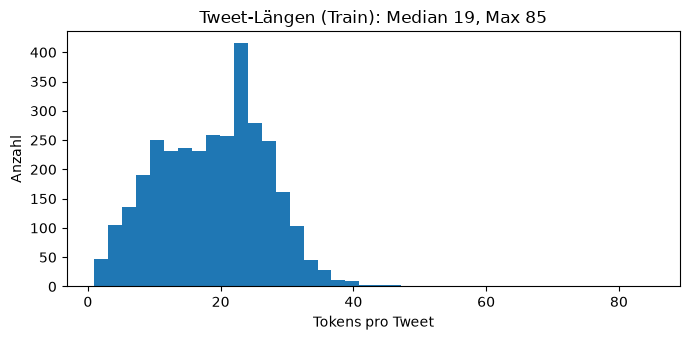

In [4]:
lengths = [len(encode(t)) for t in splits["train"][0]]
for split in ["val", "test"]:
    toks = [tok for t in splits[split][0] for tok in tokenize(t)]
    print(f"<unk>-Anteil {split}: {sum(tok not in stoi for tok in toks) / len(toks):.1%}")

plt.figure(figsize=(7, 3.5))
plt.hist(lengths, bins=40)
plt.xlabel("Tokens pro Tweet")
plt.ylabel("Anzahl")
plt.title(f"Tweet-Längen (Train): Median {np.median(lengths):.0f}, Max {max(lengths)}")
plt.tight_layout()
plt.show()

## 3. Dataset und `collate_fn`

In [5]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels):
        self.ids = [torch.tensor(encode(t), dtype=torch.long) for t in texts]
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.ids[idx], self.labels[idx]


def collate_batch(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)
    padded = pad_sequence(seqs, batch_first=True, padding_value=PAD_ID)
    return padded, lengths, torch.stack(labels)


datasets = {split: TweetDataset(*splits[split]) for split in splits}
BATCH_SIZE = 32

x, lens, y = next(iter(DataLoader(datasets["train"], batch_size=4, shuffle=False, collate_fn=collate_batch)))
print("Batch-Form (B, T):", tuple(x.shape), "| Längen:", lens.tolist(), "| Labels:", y.tolist())
print(x)

Batch-Form (B, T): (4, 21) | Längen: [21, 16, 19, 19] | Labels: [2, 0, 1, 0]
tensor([[ 414,  312,   11,    8,  154,    1,   21,    8,  568,   13,  300,  117,
           32,   20,    2,    1,    1,    2, 1768, 1168,  745],
        [  15, 1393,   41,   47,  460,   16,   60,   81, 2373,  112,   60,   32,
         1769,    2,  262, 2374,    0,    0,    0,    0,    0],
        [  54,   31,  118,   25,  817,    2,    1,   39,  569,  494,   48,    1,
          141,   31,    1, 2375,   73,   49,    1,    0,    0],
        [   1,  123,    1,  325,   57,   18,   76,  123,  415,  143,    7,    1,
           88,  818, 1394,   74,    1,   82,  214,    0,    0]])


## 4. Modell: Embedding → LSTM/GRU → Linear

In [6]:
EMBED_DIM = 128
HIDDEN_DIM = 256
NUM_CLASSES = len(CLASSES)


class RNNClassifier(nn.Module):
    def __init__(self, cell="lstm", vocab_size=len(itos), embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM,
                 num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.cell = cell
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.rnn = rnn_cls(embed_dim, hidden_dim, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, ids, lengths):
        emb = self.dropout(self.embedding(ids))                      # (B, T, D)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)
        h_n = hidden[0] if self.cell == "lstm" else hidden           # LSTM liefert (h_n, c_n)
        sentence = h_n[-1]                                           # (B, H): letzter gültiger Zustand
        return self.fc(self.dropout(sentence))                       # (B, C) Logits


for cell in ["lstm", "gru"]:
    m = RNNClassifier(cell)
    n_params = sum(p.numel() for p in m.parameters())
    n_rnn = sum(p.numel() for p in m.rnn.parameters())
    print(f"{cell.upper():4s}: {n_params:,} Parameter gesamt, davon {n_rnn:,} in der rekurrenten Schicht")

out = RNNClassifier("lstm")(x, lens)
print("Ausgabeform:", tuple(out.shape))

LSTM: 780,548 Parameter gesamt, davon 395,264 in der rekurrenten Schicht
GRU : 681,732 Parameter gesamt, davon 296,448 in der rekurrenten Schicht


Ausgabeform: (4, 4)


### Kontrolle: Padding beeinflusst die Vorhersage nicht

In [7]:
m = RNNClassifier("gru").eval()
ids = torch.tensor([encode("i am not happy about this at all")])
padded = torch.cat([ids, torch.full((1, 20), PAD_ID)], dim=1)
with torch.no_grad():
    a = m(ids, torch.tensor([ids.shape[1]]))
    b = m(padded, torch.tensor([ids.shape[1]]))
print("ohne Padding:", a.numpy().round(4))
print("mit Padding: ", b.numpy().round(4))
print("identisch:", torch.allclose(a, b, atol=1e-6))

ohne Padding: [[-0.0668 -0.1084 -0.0544  0.0639]]
mit Padding:  [[-0.0668 -0.1084 -0.0544  0.0639]]
identisch: True


## 5. Training

In [8]:
EPOCHS = 15
LR = 1e-3


def macro_f1(y_true, y_pred, num_classes=NUM_CLASSES):
    f1s = []
    for c in range(num_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        f1s.append(2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0)
    return float(np.mean(f1s)), f1s


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, preds, targets = 0.0, [], []
    for ids, lengths, labels in loader:
        ids, labels = ids.to(DEVICE), labels.to(DEVICE)
        logits = model(ids, lengths)
        total_loss += criterion(logits, labels).item() * len(labels)
        preds.append(logits.argmax(1).cpu())
        targets.append(labels.cpu())
    preds, targets = torch.cat(preds).numpy(), torch.cat(targets).numpy()
    return {"loss": total_loss / len(targets), "acc": float((preds == targets).mean()),
            "f1": macro_f1(targets, preds)[0], "preds": preds, "targets": targets}


def train_model(cell, epochs=EPOCHS, seed=SEED, verbose=True):
    set_seed(seed)
    model = RNNClassifier(cell).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, generator=g)
    val_loader = DataLoader(datasets["val"], batch_size=256, collate_fn=collate_batch)

    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
    best_f1, best_state, best_epoch = -1, None, 0
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct, n = 0.0, 0, 0
        for ids, lengths, labels in train_loader:
            ids, labels = ids.to(DEVICE), labels.to(DEVICE)
            logits = model(ids, lengths)
            loss = criterion(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            n += len(labels)
        val = evaluate(model, val_loader, criterion)
        for k, v in [("train_loss", total_loss / n), ("train_acc", correct / n),
                     ("val_loss", val["loss"]), ("val_acc", val["acc"]), ("val_f1", val["f1"])]:
            history[k].append(v)
        if val["f1"] > best_f1:
            best_f1, best_epoch = val["f1"], epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"[{cell.upper()}] Epoche {epoch:2d} | Train-Loss {total_loss / n:.3f}, Acc {correct / n:.3f} | "
                  f"Val-Loss {val['loss']:.3f}, Acc {val['acc']:.3f}, F1 {val['f1']:.3f}")
    duration = time.perf_counter() - start
    model.load_state_dict(best_state)
    if verbose:
        print(f"[{cell.upper()}] Trainingszeit {duration:.1f} s | bester Val-F1 {best_f1:.3f} in Epoche {best_epoch}")
    return model, history, best_epoch, duration


results = {}
for cell in ["lstm", "gru"]:
    results[cell] = dict(zip(["model", "history", "best_epoch", "time"], train_model(cell)))
    print()

[LSTM] Epoche  1 | Train-Loss 1.243, Acc 0.450 | Val-Loss 1.176, Acc 0.516, F1 0.347


[LSTM] Epoche  2 | Train-Loss 1.117, Acc 0.519 | Val-Loss 1.147, Acc 0.508, F1 0.367


[LSTM] Epoche  3 | Train-Loss 1.010, Acc 0.576 | Val-Loss 1.108, Acc 0.540, F1 0.388


[LSTM] Epoche  4 | Train-Loss 0.899, Acc 0.643 | Val-Loss 1.078, Acc 0.578, F1 0.460


[LSTM] Epoche  5 | Train-Loss 0.775, Acc 0.698 | Val-Loss 1.109, Acc 0.564, F1 0.444


[LSTM] Epoche  6 | Train-Loss 0.661, Acc 0.741 | Val-Loss 1.142, Acc 0.594, F1 0.494


... (20 outputs left out)

[GRU] Epoche 12 | Train-Loss 0.203, Acc 0.924 | Val-Loss 1.422, Acc 0.594, F1 0.510


[GRU] Epoche 13 | Train-Loss 0.172, Acc 0.940 | Val-Loss 1.536, Acc 0.602, F1 0.509


[GRU] Epoche 14 | Train-Loss 0.156, Acc 0.948 | Val-Loss 1.619, Acc 0.596, F1 0.527


[GRU] Epoche 15 | Train-Loss 0.121, Acc 0.955 | Val-Loss 1.703, Acc 0.615, F1 0.492
[GRU] Trainingszeit 19.3 s | bester Val-F1 0.538 in Epoche 10



## 6. Trainingskurven

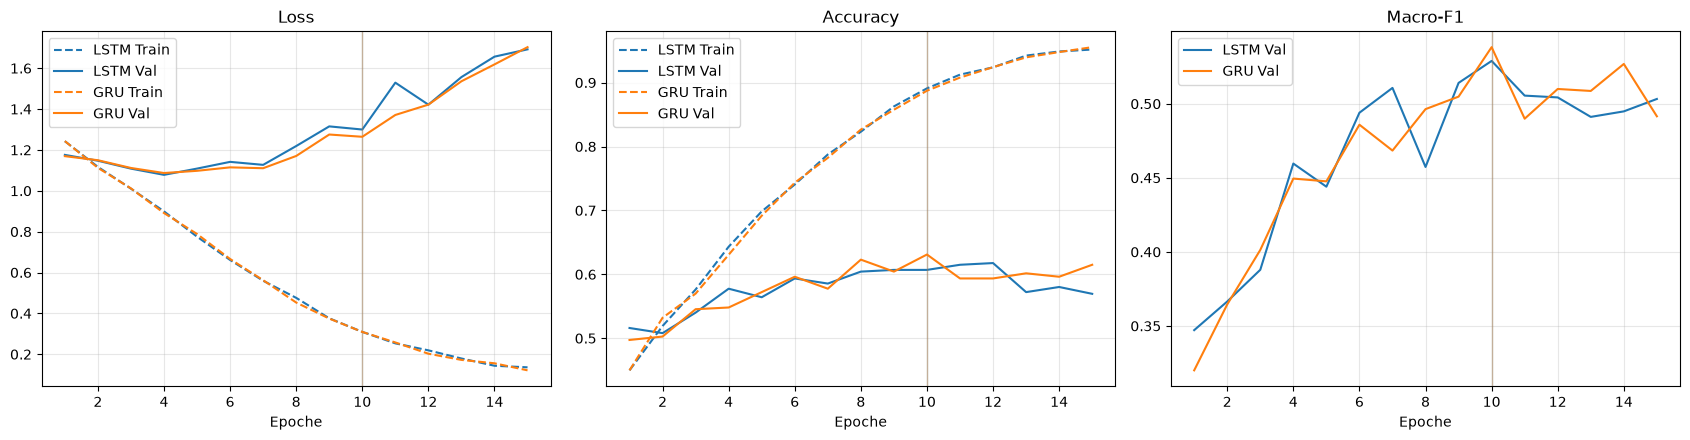

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
epochs = range(1, EPOCHS + 1)
colors = {"lstm": "tab:blue", "gru": "tab:orange"}
for cell, res in results.items():
    h, c = res["history"], colors[cell]
    axes[0].plot(epochs, h["train_loss"], c=c, ls="--", label=f"{cell.upper()} Train")
    axes[0].plot(epochs, h["val_loss"], c=c, label=f"{cell.upper()} Val")
    axes[1].plot(epochs, h["train_acc"], c=c, ls="--", label=f"{cell.upper()} Train")
    axes[1].plot(epochs, h["val_acc"], c=c, label=f"{cell.upper()} Val")
    axes[2].plot(epochs, h["val_f1"], c=c, label=f"{cell.upper()} Val")
    for ax in axes:
        ax.axvline(res["best_epoch"], c=c, alpha=0.3, lw=1)
for ax, title in zip(axes, ["Loss", "Accuracy", "Macro-F1"]):
    ax.set_title(title)
    ax.set_xlabel("Epoche")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Evaluation auf dem Testset

In [10]:
criterion = nn.CrossEntropyLoss()
test_loader = DataLoader(datasets["test"], batch_size=256, collate_fn=collate_batch)
majority = np.bincount(splits["train"][1]).argmax()
test_targets = np.array(splits["test"][1])
print(f"Baseline (immer '{CLASSES[majority]}'): Accuracy {np.mean(test_targets == majority):.3f}, "
      f"Macro-F1 {macro_f1(test_targets, np.full_like(test_targets, majority))[0]:.3f}\n")

print(f"{'Modell':6s} | {'Test-Acc':>8s} | {'Macro-F1':>8s} | " + " | ".join(f"F1 {c:>8s}" for c in CLASSES)
      + " | beste Epoche | Trainingszeit")
for cell, res in results.items():
    test = evaluate(res["model"], test_loader, criterion)
    res["test"] = test
    per_class = macro_f1(test["targets"], test["preds"])[1]
    print(f"{cell.upper():6s} | {test['acc']:8.3f} | {test['f1']:8.3f} | "
          + " | ".join(f"{f:11.3f}" for f in per_class)
          + f" | {res['best_epoch']:12d} | {res['time']:.1f} s")

Baseline (immer 'anger'): Accuracy 0.393, Macro-F1 0.141

Modell | Test-Acc | Macro-F1 | F1    anger | F1      joy | F1 optimism | F1  sadness | beste Epoche | Trainingszeit


LSTM   |    0.574 |    0.503 |       0.666 |       0.523 |       0.278 |       0.547 |           10 | 21.6 s
GRU    |    0.601 |    0.528 |       0.673 |       0.574 |       0.265 |       0.599 |           10 | 19.3 s


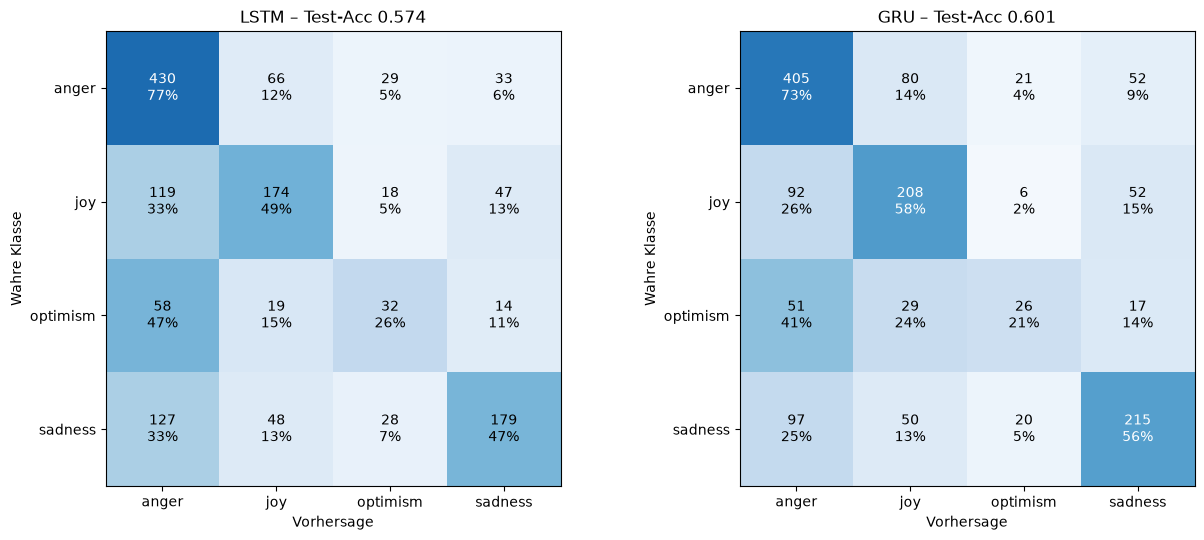

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (cell, res) in zip(axes, results.items()):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, p in zip(res["test"]["targets"], res["test"]["preds"]):
        cm[t, p] += 1
    cm_norm = cm / cm.sum(1, keepdims=True)
    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(NUM_CLASSES), CLASSES)
    ax.set_yticks(range(NUM_CLASSES), CLASSES)
    ax.set_xlabel("Vorhersage")
    ax.set_ylabel("Wahre Klasse")
    ax.set_title(f"{cell.upper()} – Test-Acc {res['test']['acc']:.3f}")
plt.tight_layout()
plt.show()

### Robustheit: mehrere Seeds

In [12]:
SEEDS = [0, 1, 2, 3, 4]
seed_scores = {cell: [] for cell in ["lstm", "gru"]}
for seed in SEEDS:
    for cell in seed_scores:
        model, _, best_epoch, _ = train_model(cell, seed=seed, verbose=False)
        test = evaluate(model, test_loader, criterion)
        seed_scores[cell].append((test["acc"], test["f1"]))
    print(f"Seed {seed}: " + " | ".join(
        f"{c.upper()} Acc {seed_scores[c][-1][0]:.3f}, F1 {seed_scores[c][-1][1]:.3f}" for c in seed_scores))

print()
for cell, scores in seed_scores.items():
    acc, f1 = np.array(scores).T
    print(f"{cell.upper():4s}: Test-Acc {acc.mean():.3f} ± {acc.std():.3f} | Macro-F1 {f1.mean():.3f} ± {f1.std():.3f}")
diff = np.array(seed_scores["gru"]) - np.array(seed_scores["lstm"])
print(f"GRU − LSTM pro Seed (Acc): {np.round(diff[:, 0], 3).tolist()}")

Seed 0: LSTM Acc 0.597, F1 0.525 | GRU Acc 0.600, F1 0.535


Seed 1: LSTM Acc 0.583, F1 0.527 | GRU Acc 0.592, F1 0.538


Seed 2: LSTM Acc 0.581, F1 0.507 | GRU Acc 0.612, F1 0.552


Seed 3: LSTM Acc 0.572, F1 0.506 | GRU Acc 0.599, F1 0.529


Seed 4: LSTM Acc 0.605, F1 0.533 | GRU Acc 0.600, F1 0.532

LSTM: Test-Acc 0.588 ± 0.012 | Macro-F1 0.520 ± 0.011
GRU : Test-Acc 0.601 ± 0.007 | Macro-F1 0.537 ± 0.008
GRU − LSTM pro Seed (Acc): [0.004, 0.008, 0.032, 0.027, -0.005]


### Beispielvorhersagen

In [13]:
@torch.no_grad()
def predict_texts(model, texts):
    model.eval()
    seqs = [torch.tensor(encode(t)) for t in texts]
    ids = pad_sequence(seqs, batch_first=True, padding_value=PAD_ID).to(DEVICE)
    lengths = torch.tensor([len(s) for s in seqs])
    return model(ids, lengths).softmax(1).cpu()


samples = ["I am so happy today, best day ever!",
           "I am not happy at all, this is terrible",
           "Why does everything always go wrong?! #furious",
           "Tomorrow will be better, never give up",
           "I miss you so much, feeling lonely tonight"]
probs = {cell: predict_texts(res["model"], samples) for cell, res in results.items()}
for i, text in enumerate(samples):
    line = " | ".join(f"{cell.upper()}: {CLASSES[p[i].argmax()]} ({p[i].max():.0%})" for cell, p in probs.items())
    print(f"{text:48s} → {line}")

print("\nFehlklassifizierte Test-Tweets (LSTM):")
test_texts = splits["test"][0]
wrong = np.where(results["lstm"]["test"]["preds"] != results["lstm"]["test"]["targets"])[0]
for idx in wrong[:6]:
    print(f"  wahr={CLASSES[test_targets[idx]]:8s} LSTM={CLASSES[results['lstm']['test']['preds'][idx]]:8s} "
          f"GRU={CLASSES[results['gru']['test']['preds'][idx]]:8s} | {test_texts[idx][:90]}")

I am so happy today, best day ever!              → LSTM: joy (99%) | GRU: joy (78%)
I am not happy at all, this is terrible          → LSTM: anger (69%) | GRU: sadness (64%)
Why does everything always go wrong?! #furious   → LSTM: anger (99%) | GRU: anger (98%)
Tomorrow will be better, never give up           → LSTM: optimism (57%) | GRU: optimism (64%)
I miss you so much, feeling lonely tonight       → LSTM: sadness (84%) | GRU: sadness (94%)

Fehlklassifizierte Test-Tweets (LSTM):
  wahr=sadness  LSTM=anger    GRU=optimism | #Deppression is real. Partners w/ #depressed people truly dont understand the depth in whi
  wahr=anger    LSTM=joy      GRU=sadness  | @user Interesting choice of words... Are you confirming that governments fund #terrorism? 
  wahr=joy      LSTM=anger    GRU=anger    | What makes you feel #joyful? 
  wahr=anger    LSTM=joy      GRU=joy      | i am revolting. 
  wahr=sadness  LSTM=anger    GRU=joy      | @user @user #cmbyn does screen  August 4 &amp; 6 at #miff 